# Preliminary Forecasts: Univariate Models

**Goal:** For each operating reactor, forecast its average power output (as a % of full power) for the **next quarter**, so that a data center relying on that reactor knows in advance whether to expect a drop and how large it will be.

From our work in `get_reactor_data.ipynb`, we learned two things:

1. Over 26 years, refueling outages account for about 81% of all zero-power days. 
2. Unplanned outages are the most common type by count (44% of outages), but they are short and make up only 12.8% of outage days.

We use the cleaned reactor data from `get_reactor_data.ipynb`. All the methods here are **univariate**: each forecast uses only that reactor's past power values, with no other features.

We compare four methods, going from simple baselines to more flexible models, and explain each one as we go:

1. **Seasonal naive**: repeat the most recent refueling cycle.
2. **Seasonal average**: average the same point over the last few refueling cycles.
3. **Holt-Winters (exponential smoothing)**: a level and a seasonal pattern that update as new data comes in.
4. **Seasonal ARIMA (SARIMA)**: models each quarter's power from past quarters and from the same point in previous cycles.

Here the "season" is the reactor's **refueling cycle** (18 or 24 months), not the calendar year.

**How we evaluate.** Since the goal is a next-quarter forecast, we test the models the same way. We split the data in two:

- **Tuning period (2000–2022):** used only to choose each model's settings: the number of cycles to average, Holt-Winters' $\alpha$ and $\gamma$, and the SARIMA orders. These are then fixed.
- **Test period (2023–2025, 12 quarters):** used only to score the models. We forecast **walk-forward**: at the start of each test quarter, a model forecasts that quarter using all data up to the end of the previous quarter. Then the actual value is added to the history and the model moves on to the next quarter.
- **Recent history only:** the forecasts only use each reactor's last few refueling cycles before the quarter being forecast: 3 for the seasonal average, 4 for Holt-Winters and SARIMA. Some reactors changed cycle length over the years, so older cycles don't line up with today's quarters.

## Loading the data

We load the cleaned daily power reports for 2000–2025 and average them into **quarterly power** for each reactor, since that is what we forecast. We also keep each quarter's start date. We use it to order the quarters, to separate the tuning and test periods, and to look up each reactor's refueling history as of that date.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Our cleaned reactor data lives here
outdir = Path("/Users/vassu/Desktop/Erdos_DataScience/NuclearReliability/reactor_data/cleaned_data/")

# load the data. We need to pass on the parse_dates option so that we can perform operations on the date column
# By default the date column will be treated as a string (because of the dashes)

all_years = []

for year in range(2000, 2026):

    df = pd.read_csv(outdir/f"CleanedData_{year}.csv", sep="\t", parse_dates=["date"])
    all_years.append(df)

df = pd.concat(all_years, ignore_index=True)

# Using the dates Column to define a quarter period
df["quarter_period"] = df["date"].dt.to_period("Q")

In [2]:
# groupby turns Unit, Region and quarter_period into the index, with the mean as the only column.
# reset_index moves them back into regular columns.

quarter_df = df.groupby(["Unit", "Region", "quarter_period"])["Power"].agg(["mean"]).reset_index()
quarter_df = quarter_df.rename(columns={"mean": "average_power"})

quarter_df["quarter_start"] = quarter_df["quarter_period"].dt.start_time

# We drop the Watts Bar 2 quarters before October 2016 (its commissioning period, not normal operation) 
# and leave out Vogtle 3 and 4, which started operating too recently (not enough data). This leaves 92 reactors.

commissioning = (quarter_df["Unit"] == "Watts Bar 2") & (quarter_df["quarter_start"] < "2016-10-01")
quarter_df = quarter_df[~commissioning]

quarter_df = quarter_df[ ~quarter_df["Unit"].isin(["Vogtle 3", "Vogtle 4"])  ].reset_index(drop=True)

## Quarterly power over time

Before choosing any forecasting method, let's look at what the series look like. Below we plot the quarterly average power for each reactor in Region 1 from 2000 to 2025.

Things to look for:
- **Trend:** does power drift up or down over the years?
- **Repeating patterns:** are there regular drops, and how far apart are they?
- **One-off events:** are there drops that don't follow any pattern?

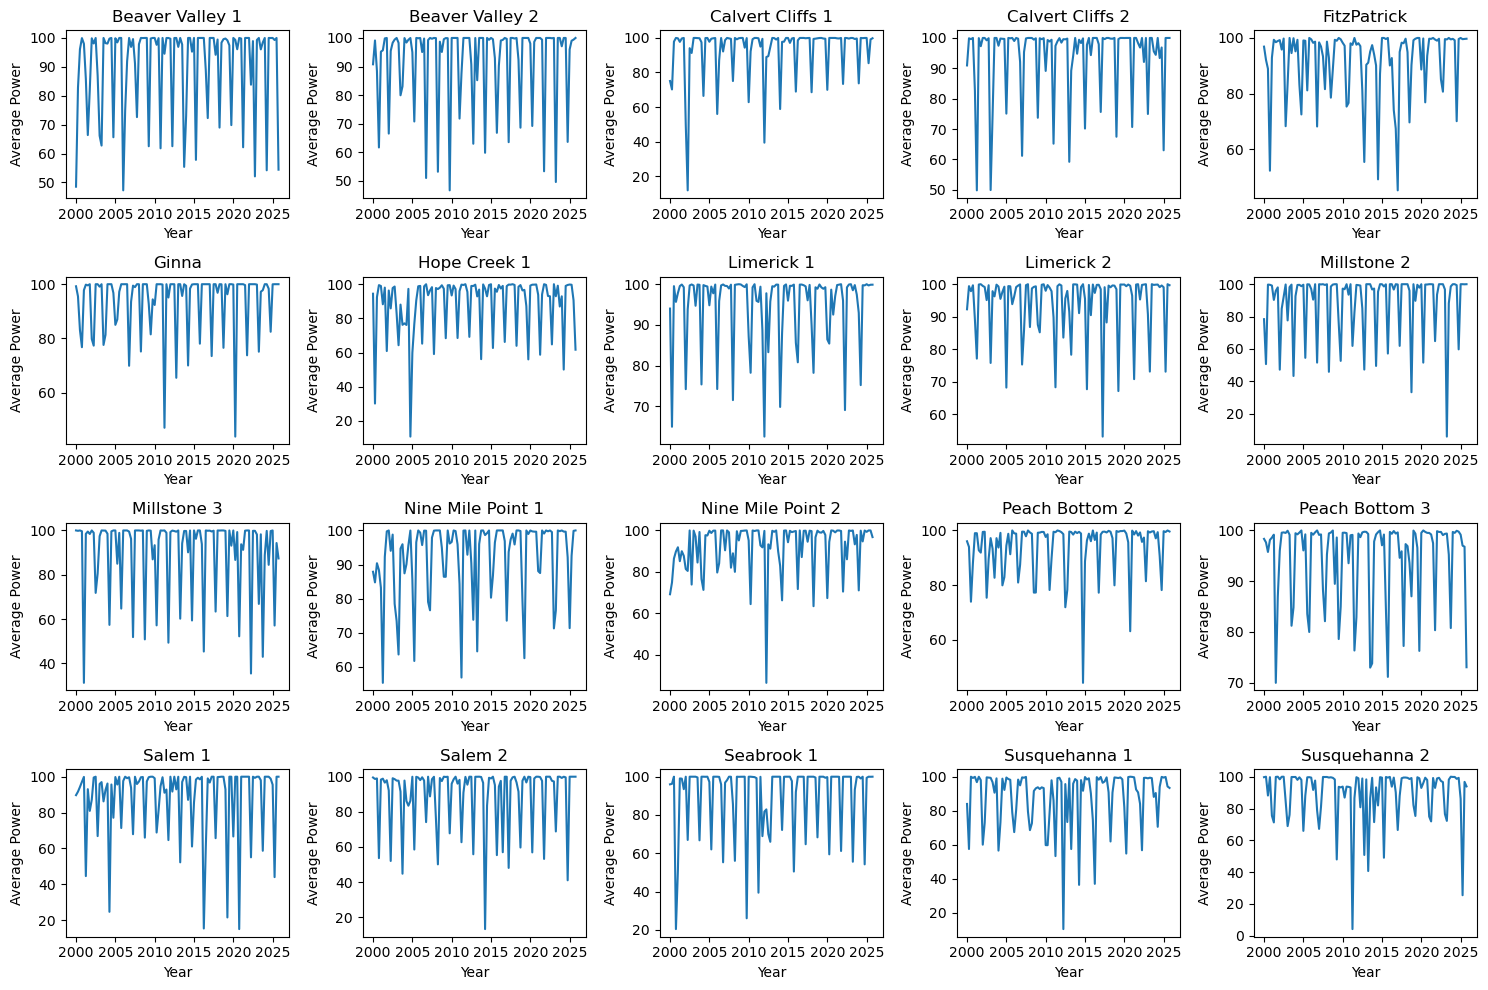

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import math

region = "Region 1"
regional_df = quarter_df[ quarter_df["Region"] == region ]
n_reactors = regional_df["Unit"].nunique()
reactors = regional_df["Unit"].unique()

n_rows = 4
n_columns = math.ceil(n_reactors/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15,10))
axes = axes.flatten()

for i in range(n_reactors):
    axes[i].plot(regional_df[regional_df["Unit"] == reactors[i]]["quarter_start"], regional_df[regional_df["Unit"] == reactors[i]]["average_power"])
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Average Power")
    axes[i].set_title(f'{reactors[i]}')
    axes[i].xaxis.set_major_locator(mdates.YearLocator(5))
plt.tight_layout()
plt.show()

Most reactors run close to 100% power, with sharp drops at regular intervals. These are the refueling outages. There is no long-term trend, but the series is clearly seasonal, and the season length differs between reactors. There are also occasional drops that don't follow the cycle, such as unplanned outages or refuelings that ran much longer than usual.
 
Next we measure each reactor's refueling cycle: for every refueling outage, the time from the end of the previous refuel to the start of this one.

In [4]:
# Load the outages data
outages_df = pd.read_csv(outdir/"outages_data.csv", sep="\t", parse_dates=["Start_Date", "End_Date"])

refueling_df = outages_df[ outages_df["outage_reason"] == "refueling outage" ].sort_values(["Unit", "Start_Date"]).reset_index(drop=True)

# For each refueling outage: time from the end of the previous 
# refuel to the start of this one, in quarters (91 days ~ 1 quarter).
# shift(1) within each Unit gives the previous refuel of the same reactor
# A reactor's first refuel has no previous one, so it gets NaN.

refueling_df["quarters_since_last_refuel"] = (refueling_df["Start_Date"] - refueling_df.groupby("Unit")["End_Date"].shift(1)).dt.days/(91)

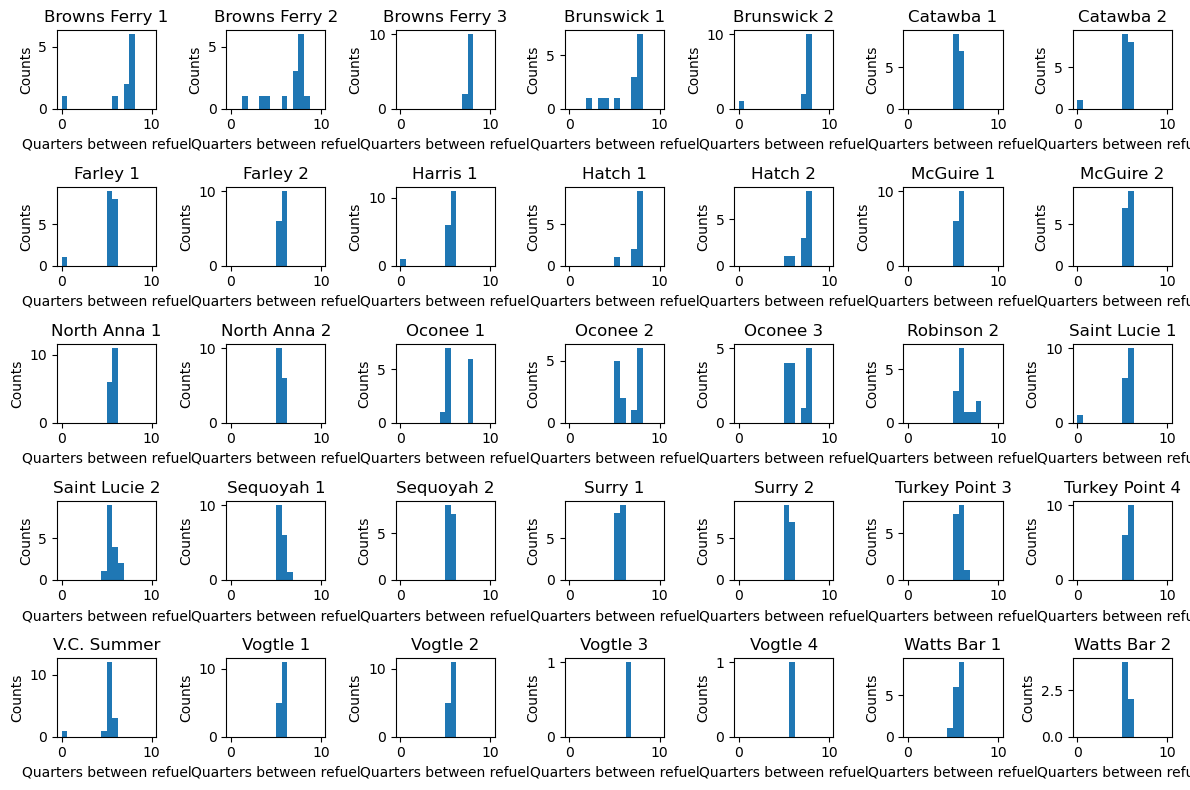

In [19]:
region = "Region 2"
regional_df = refueling_df[ refueling_df["Region"] == region ]
reactors = regional_df["Unit"].unique()

n_rows = 5
n_columns = math.ceil(len(reactors)/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(12,8))
axes = axes.flatten()

for i in range(len(reactors)):

    axes[i].hist(regional_df[ regional_df["Unit"] == reactors[i]]["quarters_since_last_refuel"], bins=16, range=(0, 10))
    axes[i].set_xlabel("Quarters between refuel")
    axes[i].set_ylabel("Counts")
    axes[i].set_title(f'{reactors[i]}')

plt.tight_layout()
plt.show()

Most reactors fall clearly into one of two groups: an **18-month** or a **24-month** refueling cycle. Many reactors, however, are a mix of the two, either because they switched cycle length at some point (for example Oconee 1–3 and Robinson 2 in Region 2) or because some intervals were stretched by long forced outages. This makes it hard to assign one cycle length to a reactor's whole history.

The nominal 18- and 24-month cycles are measured from the start of one refueling to the start of the next, so they **include** the refueling outage itself. Here we measure the time between outages, from the end of one refuel to the start of the next, which leaves out the outage. That is why the histograms peak a little below 6 and 8 quarters, not exactly at them.

Since our forecasts look forward, what matters most is the cycle a reactor is on **now**. So we define each reactor's cycle length from its most recent behaviour: the **median of its last 3 refueling intervals**. The median keeps one unusual interval from distorting the result. We then assign the cycle length in quarters: **6** (18 months) if the median is below 7, otherwise **8** (24 months). The threshold of 7 sits between the two groups, so the shorter end-to-start intervals still fall in the right group.

*We have to be careful about **when** we measure this. For each quarter we forecast, the cycle length uses only refuels that **ended before that quarter starts**. Using later refuels would give the forecast information from the future it is trying to predict.*


In [6]:
# Cycle length (6 or 8 quarters) of a reactor, as known at a given date (cutoff).
# It is called with the start date of every quarter we forecast,
# so it only uses refuels that had ENDED before that date: no information from the future.
#
# Intervals shorter than 4 quarters are mid-cycle outages, not real cycles, so they are skipped.
# We take the median of the last n_recent intervals, so the cycle follows recent changes but one 
# odd interval doesn't dominate. The 7-quarter threshold sits between the two groups 
# (our intervals exclude the outage itself, so they come out slightly under 6 and 8).
# Returns 0 if the reactor has no usable refuel history yet, meaning "no forecast possible".

def get_cycle_quarters(unit, cutoff, n_recent=3):

    mask = (refueling_df["End_Date"] < cutoff) & (refueling_df["quarters_since_last_refuel"] >= 4) & (refueling_df["Unit"] == unit)
    past = refueling_df[mask]

    if len(past) == 0:
        return 0

    length = past["quarters_since_last_refuel"].tail(n_recent).median()
    return 6 if length < 7 else 8

## Baseline forecasts

Our quarterly power has no long-term trend but repeats with the refueling cycle. The simplest way to forecast a series like this is to look back **one or more full cycles** and copy what happened at the same point.

To forecast quarter $t$, let $T$ be the reactor's cycle length (6 or 8 quarters) as known at the start of quarter $t$, and $y_t$ the average power in quarter $t$.

**Seasonal naive:** use the value from exactly one cycle ago.

$$
\hat{y}_t = y_{t-T}
$$

For example, on an 8-quarter cycle, the forecast for 2025Q1 is the actual power in 2023Q1. If the reactor refueled then, we predict a refueling drop now.

- *Strength:* follows the most recent cycle, so it adapts quickly if the cycle shifts.
- *Weakness:* relies on a single past value, so one unusual quarter (for example a long forced outage) is copied straight into the forecast.

**Seasonal average:** average the same point over the last $k$ cycles.

$$
\hat{y}_t = \frac{1}{k} \sum_{i=1}^{k} y_{t-iT}
$$

With $k = 1$ this is the seasonal naive forecast. A larger $k$ smooths out one-off events, but reaches further into the past. If a reactor has fewer than $k$ past cycles, we average over the ones it has.

We will not average over *all* past cycles. Cycles drift by a few months over the years, and some reactors switched from 18 to 24 months. So old cycles don't line up with today's quarters, and averaging them in would blur the refueling drops. A small $k$ is a compromise. To choose it, we run the seasonal average walk-forward over the tuning period for several values of $k$ and keep the one with the lowest error (next cell).

In [7]:
from sklearn.metrics import root_mean_squared_error as rmse
from sklearn.metrics import mean_absolute_error as mae

cutoffs = pd.to_datetime(["2009-01-01", "2011-01-01", "2013-01-01", "2015-01-01", "2017-01-01" , "2020-01-01"])
cycles_considered = [2, 3, 4, 5]
scores=[]

# Choosing k (the number of past cycles to average) for the seasonal average.
# Nothing is fitted here: for each candidate k we make walk-forward, one-quarter-ahead forecasts
# over the tuning period (defined in the cut offs) and compare the errors.

for unit, unit_df in quarter_df.groupby("Unit"):

    y = unit_df["average_power"].to_numpy()

    for i in range(len(cutoffs)-1):

        mask = (unit_df["quarter_start"] >= cutoffs[i]) & (unit_df["quarter_start"] < cutoffs[i+1])
        training_data = unit_df[mask]

        # Position of the window's first quarter in y (summing True/False counts the quarters before the window)
        start = (unit_df["quarter_start"] < cutoffs[i]).sum()

        # A reactor might not have data for the cutoff period considered
        # Putting a safeguard for that
        if len(training_data) == 0:
            continue

        for cycle in cycles_considered:

            actual = []
            forecast = []

            for j, quarter_start in enumerate(training_data["quarter_start"]):

                # Cycle length as known at the start of this quarter (no future refuels)
                # Our walk forward forecast idea
                length = get_cycle_quarters(unit, quarter_start)

                if (length == 0):
                    continue

                # j+start is the position of this quarter in the y array
                cycles_available = (j+start) //  length
                k = min(cycle, cycles_available)

                # Without this safeguard vals would be empty and np.mean([]) would return NaN
                if k == 0:
                    continue

                vals = [ y[ (j+start) - i*length] for i in range(1, k+1)]
                forecast.append(np.mean(vals))
                actual.append( y[j+start])

            # This is important because an empty forecast/actual array passed into the mae/rmse
            # function will raise an error (annoying)
            if len(actual) == 0:
                continue

            scores.append({"Unit": unit, "cut_off_start": cutoffs[i], "cut_off_end": cutoffs[i+1], "cycles": cycle, "RMSE": rmse(actual, forecast), "MAE": mae(actual, forecast) })


scores = pd.DataFrame(scores)
scores.groupby(["cycles"])[["RMSE", "MAE"]].agg(["mean"])

,RMSE,MAE
,mean,mean
cycles,,
2,11.959066,8.065668
3,11.765951,8.040362
4,11.749570,8.185155
5,11.780572,8.322660


All values of $k$ give very similar errors: the mean MAE ranges from 8.04 to 8.32, so the seasonal average is not very sensitive to how many cycles we average over.

We choose **$k = 3$**, which has the lowest mean MAE. RMSE would pick $k = 4$ by a tiny margin, but we rely on MAE. RMSE squares the errors, so it is dominated by a few very large misses, such as unplanned or unusually long outages that no seasonal model can predict. MAE weighs every quarter fairly equally and better reflects typical forecast accuracy.


In [20]:
cycles_considered = 3

for unit, unit_df in quarter_df.groupby("Unit"):

    y = unit_df["average_power"].to_numpy()
    seasonal_naive = []
    seasonal_average = []

    # For a walk forward forecast we need to go row by row
    # quarter_start basically helps us define the cycle length
    # using refuel data before this date
    for j, quarter_start in enumerate(unit_df["quarter_start"]):

        length = get_cycle_quarters(unit, quarter_start)

        # if the forecast is not possible because there is not enough
        # refueling history yet or not even one full cycle of data before this quarter
        if (length == 0) or (j-length < 0):
            seasonal_naive.append(np.nan)
            seasonal_average.append(np.nan)
            continue

        # The value of this quarter in the previous cycle
        seasonal_naive.append(y[j-length])

        # Depending on where we are, the cycles available might be smaller than required for forecast
        cycles_available = j // length
        k = min(cycles_considered, cycles_available)

        if k == 0:
            seasonal_average.append(np.nan)
            continue

        vals = [ y[j-i*length] for i in range(1, k+1) ]
        seasonal_average.append(np.mean(vals))

    quarter_df.loc[ unit_df.index, "seasonal_naive" ] = seasonal_naive
    quarter_df.loc[ unit_df.index, "seasonal_average"] = seasonal_average

quarter_df.sample(5)

,Unit,Region,quarter_period,average_power,quarter_start,seasonal_naive,seasonal_average,holt_winter,arima
4220,La Salle 1,Region 3,2015Q1,99.722222,2015-01-01,99.611111,95.885185,96.085028,NaN
1367,Callaway,Region 4,2003Q4,95.847826,2003-10-01,99.010989,99.467451,99.229076,NaN
6461,Point Beach 1,Region 3,2003Q2,99.494505,2003-04-01,98.163043,97.878225,100.340510,NaN
9012,Vogtle 1,Region 2,2017Q1,73.644444,2017-01-01,88.152174,84.646860,83.515427,NaN
530,Braidwood 2,Region 3,2002Q3,96.489130,2002-07-01,99.177778,99.177778,NaN,NaN


## Holt-Winters (exponential smoothing)

The seasonal baselines give every past cycle in their window the **same weight** (at least we set it up that way with the seasonal average forecast). Exponential smoothing instead gives **more weight to recent data**, with older observations fading out gradually.

The full Holt-Winters method tracks three components: a **level**, a **trend** and a **seasonal pattern**. Our series has no trend, so we keep only the level and an additive seasonal pattern. With $T$ the cycle length in quarters, after observing quarter $t$ we update:

$$
\begin{aligned}
\text{Level:} \quad & \ell_t = \alpha\,(y_t - s_{t-T}) + (1-\alpha)\,\ell_{t-1} \\
\text{Season:} \quad & s_t = \gamma\,(y_t - \ell_{t-1}) + (1-\gamma)\,s_{t-T}
\end{aligned}
$$

and the one-quarter-ahead forecast is

$$
\hat{y}_t = \ell_{t-1} + s_{t-T}
$$

- The **level** $\ell_t$ is the reactor's typical power once the seasonal effect is removed.
- The **seasonal term** $s_t$ is how far each point in the cycle sits above or below the level.
- So the forecast is: the current level, plus how far this point in the cycle usually sits from it.

The two smoothing parameters, between 0 and 1, control how quickly each component adapts:
- **$\alpha$** (level): close to 1 means the level follows the latest quarters closely; close to 0 means it changes slowly.
- **$\gamma$** (season): close to 1 means the seasonal pattern is driven by the most recent cycle (like seasonal naive); close to 0 means it is averaged over many cycles (like the seasonal average).

So Holt-Winters sits between our two baselines, and the data decide where.

**Choosing $\alpha$ and $\gamma$.** For each reactor we try every pair $\alpha, \gamma \in \{0.1, 0.2, \dots, 0.9\}$. At each cutoff in the tuning period (2009–2020), we fit the model on the **last 4 cycles** before the cutoff, forecast the **next full cycle**, and compute the MAE. We keep the pair with the lowest average MAE across cutoffs. We use only the last 4 cycles because, as noted above, some reactors changed cycle length over the years, and older cycles would not line up with the cycle length the model uses. Holt-Winters needs at least two full cycles of history to start, so cutoffs with less history are skipped.

Note that we tune on a full-cycle forecast, even though we use the model only one quarter ahead. With a handful of cutoffs, scoring only the next quarter would give very few points per reactor to compare 81 parameter pairs, and might miss the refueling drop entirely. A full cycle always contains a refueling drop and gives several points per cutoff. The trade-off is that the chosen $\alpha$ and $\gamma$ are best for a full-cycle forecast, and might not be exactly the best for one quarter ahead.

**Walk-forward:** with $\alpha$ and $\gamma$ fixed, we refit the model for every quarter on all quarters before it and forecast that one quarter.


In [9]:
# In order to test against every combination of alphas and gammas we will use the "itertools" library
# We will use the same cutoffs as defined above

import itertools as itr
from statsmodels.tsa.api import ExponentialSmoothing

# This is an awesome library
from tqdm.auto import tqdm

alphas = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
gammas = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

combinations = list(itr.product(alphas, gammas))

results= {}

for unit, unit_df in tqdm(quarter_df.groupby("Unit"), desc="Grid Search"):

    best_score = np.inf

    for alpha, gamma in combinations:

        fold_scores = []

        for cut_off in cutoffs:

            length = get_cycle_quarters(unit, cut_off)

            if length == 0:
                continue

            # Much easier to work with a numpy array
            train_set = unit_df[ unit_df["quarter_start"] < cut_off ]["average_power"].to_numpy()[-4*length:]
            val_set = unit_df[ unit_df["quarter_start"] >= cut_off ]["average_power"].to_numpy()[:length]
    
            # For initilization the model needs at least two full seasonal cycles apparently
            # one cycle for initilization and one for the update

            # If there is nothing in the validation set that is also useless
    
            if len(train_set) < 2*length or len(val_set) == 0:
                continue

            model = ExponentialSmoothing( train_set, seasonal='add', seasonal_periods=length).fit(smoothing_level=alpha, smoothing_seasonal=gamma, optimized=False)

            fold_scores.append(mae(val_set, model.forecast(len(val_set))))

        if len(fold_scores) == 0:
            continue

        score = np.mean(fold_scores)

        if score < best_score:
            best_score = score
            results[unit] = { "alpha": alpha, "gamma": gamma, "score": score } 

Grid Search:   0%|          | 0/92 [00:00<?, ?it/s]

In [ ]:
for unit, unit_df in quarter_df.groupby("Unit"):

    y = unit_df["average_power"].to_numpy()

    # Every reactor has tuned values (checked: no reactor is missing from results).
    alpha = results[unit]["alpha"]
    gamma = results[unit]["gamma"]

    holt_winter=[]
    
    for j, quarter_start in enumerate(unit_df["quarter_start"]):

        length = get_cycle_quarters(unit, quarter_start)

        if (length == 0) or (j < 2*length):
            holt_winter.append(np.nan)
            continue

        # only keeping the past 4 cycles
        model = ExponentialSmoothing(y[:j][-4*length:], seasonal='add', seasonal_periods=length).fit(smoothing_level=alpha, smoothing_seasonal=gamma, optimized=False)

        holt_winter.append(model.forecast(1)[0])

    quarter_df.loc[unit_df.index, "holt_winter"] = holt_winter

## Seasonal ARIMA (SARIMA)

The baselines and Holt-Winters follow a fixed recipe: the forecast is built from the same point in past cycles, and we only tune how much weight each cycle gets. **SARIMA** is more flexible. It writes each quarter's power as a combination of earlier quarters (for example the previous quarter, or the same point one cycle ago) and of past random shocks (the noise terms), and estimates from the data which of these terms matter and how much. To get an idea of the sensible model orders, we first look at two diagnostic plots:

- **Autocorrelation function (ACF):** the correlation between the series and itself shifted by $k$ quarters. A large value at lag $k$ means a quarter tells us a lot about the quarter $k$ steps later.
- **Partial autocorrelation function (PACF):** the same correlation, but after removing the effect of all shorter lags. It shows which lags carry **new** information.

What to look for:
- **Peaks at multiples of the cycle length** (lags 6, 12, 18, … or 8, 16, 24, …) confirm the refueling seasonality and suggest seasonal terms.
- **Spikes at the first few lags** show short-term memory, for example a strong quarter tending to follow another strong one.
- As a rule of thumb, a PACF that cuts off after a few lags points to **autoregressive (AR)** terms, and an ACF that cuts off points to **moving-average (MA)** terms.

The shaded band marks the 95% significance level: spikes inside it are indistinguishable from noise.

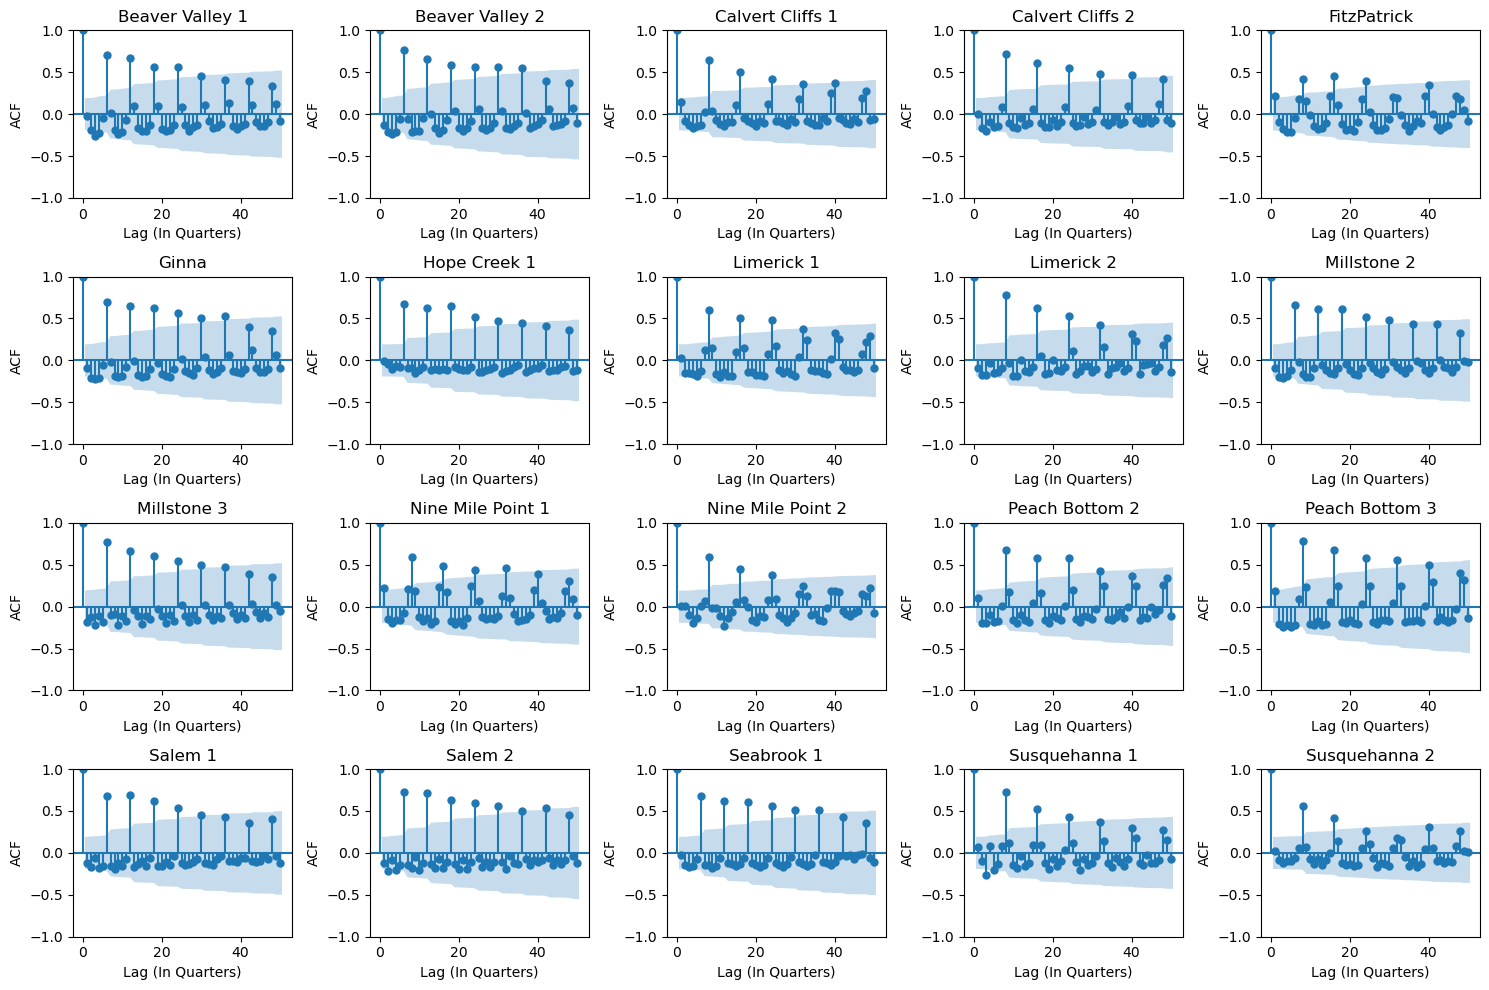

In [11]:
import statsmodels.api as sm

region = "Region 1"

regional_df = quarter_df[ quarter_df["Region"] == region ]
reactors = regional_df["Unit"].unique()

n_rows = 4
n_columns = math.ceil(len(reactors)/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 10))
axes = axes.flatten()

for i in range(len(reactors)):  

    sm.graphics.tsa.plot_acf(regional_df[ regional_df["Unit"] == reactors[i] ]["average_power"].reset_index(drop=True), lags=50, ax=axes[i])

    axes[i].set_xlabel("Lag (In Quarters)")
    axes[i].set_ylabel("ACF")
    axes[i].set_title(f'{reactors[i]}')

plt.tight_layout()
plt.show()

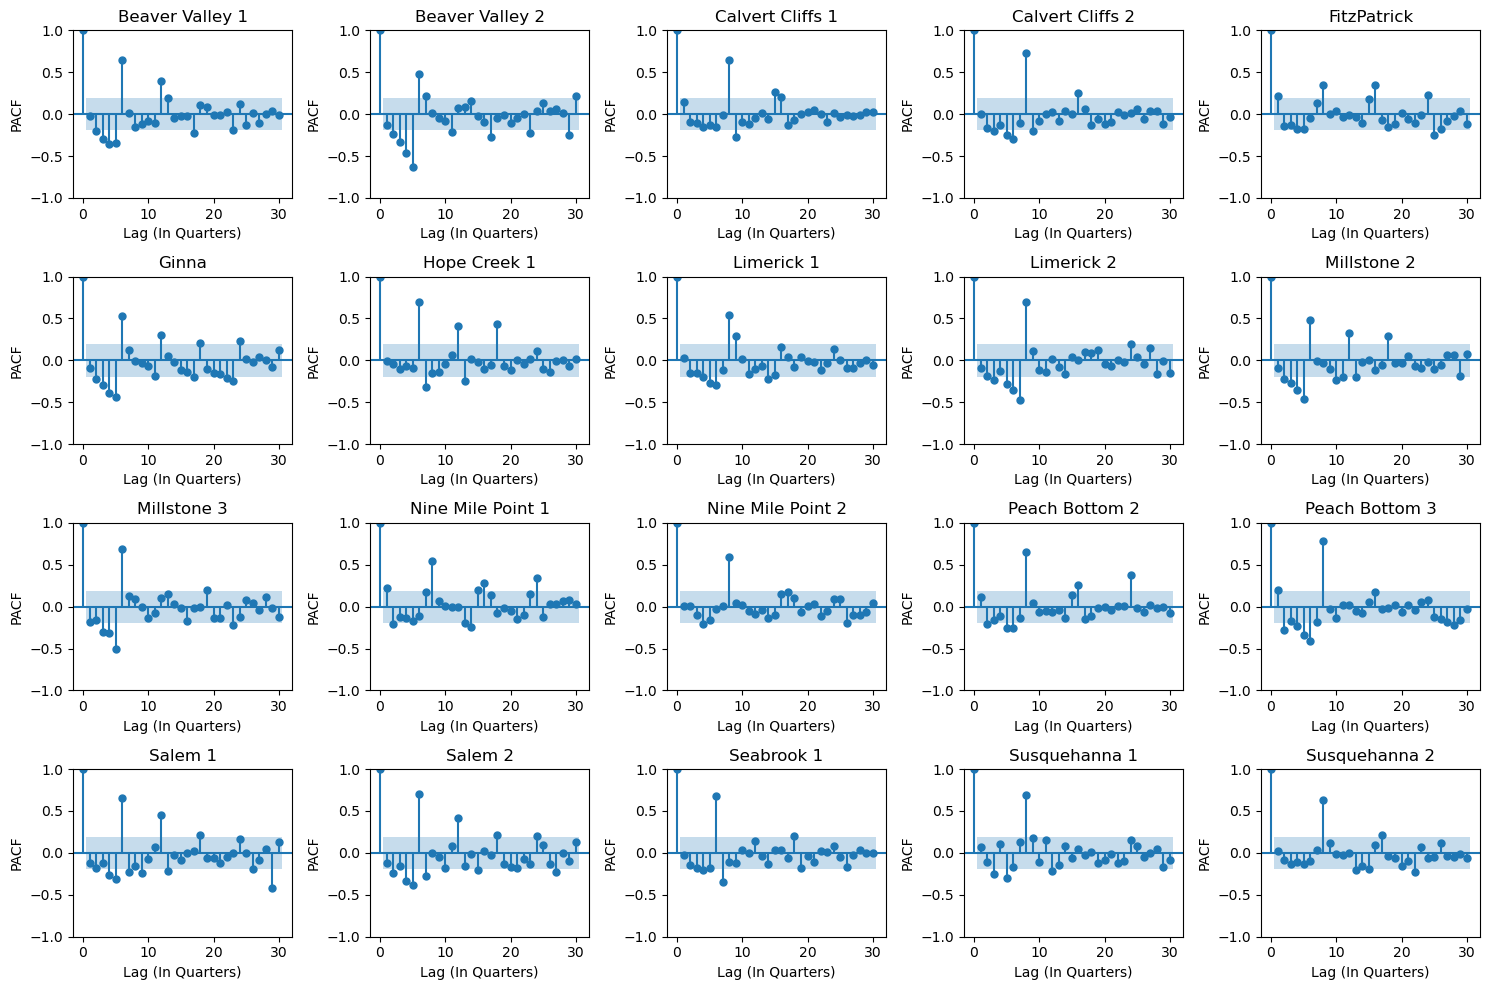

In [12]:
fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 10))
axes = axes.flatten()

for i in range(len(reactors)):  

    sm.graphics.tsa.plot_pacf(regional_df[ regional_df["Unit"] == reactors[i] ]["average_power"].reset_index(drop=True), lags=30, method = 'ols', ax=axes[i])

    axes[i].set_xlabel("Lag (In Quarters)")
    axes[i].set_ylabel("PACF")
    axes[i].set_title(f'{reactors[i]}')

plt.tight_layout()
plt.show()

Most reactors show clear ACF peaks at multiples of their cycle length, which confirms the seasonality, but the peaks are weak and fade quickly. This is consistent with cycles drifting by a few months over time, so outages do not line up exactly every 6 or 8 quarters. Short-lag correlations are small, so we expect low non-seasonal orders. Instead of choosing the orders by hand for 92 reactors, we let `auto_arima` search for them, using these plots as a sanity check.

### Fitting SARIMA

For each reactor, `auto_arima` searches for the model orders on the **last 4 refueling cycles before 2023** and picks the model with the lowest AIC. We fix:

- `m = T`: the seasonal period is the reactor's cycle length as known at the start of 2023.
- `D = 1`: one seasonal difference. The model works with $y_t - y_{t-T}$, the change from the same point one cycle earlier, which removes the repeating refueling pattern. This is the "Integrated" part of SARIMA.
- `d = 0`: no ordinary differencing, since the series has no trend.

**Why only the last 4 cycles?** As mentioned earlier, some reactors changed cycle length over the years.

**Why not tune SARIMA over the cutoffs like Holt-Winters?** The two choices are different. Holt-Winters' $\alpha$ and $\gamma$ are weights: they set how quickly the model forgets old data, which we expect to be a fairly stable property of each reactor, so we check them at many cutoffs. SARIMA's orders instead decide *which terms* the model contains, and they are tied to the cycle length $m$. Since the SARIMA model is fitted once, with the cycle length known at the start of 2023, and used only for 2023–2025, we choose its orders on the 4 cycles just before that, using AIC, which balances fit against the number of terms. SARIMA's own "weights on the past", its coefficients, are then estimated from the data and updated during the walk-forward.

**Walk-forward:** in the test period we forecast one quarter, then add its actual value with `model.update()` before forecasting the next. The orders stay fixed. Unlike the other models, SARIMA's cycle length is set once at the start of 2023 and not re-checked each quarter, so it cannot follow a reactor that changes cycle during the test period.

**In-sample values:** for the quarters in the window we also store the model's one-step predictions, but **only for the plots**. The coefficients were fitted on those same quarters, so they are not true forecasts.



In [13]:
from pmdarima import auto_arima, ARIMA

# Here we define training preiod to get the orders
training_period = pd.Timestamp("2023-01-01")

sarima_models = {}

for unit, unit_df in tqdm(quarter_df.groupby("Unit"), desc="SARIMA"):

    y = unit_df["average_power"].to_numpy()

    # number of training quarters, and the cycle length known at the start of the test period
    n_train = (unit_df["quarter_start"] < training_period).sum()
    length = get_cycle_quarters(unit, training_period)

    # Needs at least 2 cycles: one is used up by the seasonal difference, 
    # at least one to estimate the coefficients

    if (length == 0) or (n_train < 2*length):
        continue

    start = max(0, n_train-4*length)

    # Choose the orders once, on the training quarters only (auto_arima compares models by AIC)
    best = auto_arima(y[start:n_train], seasonal=True, m=length, error_action="ignore", d=0, D=1)
    model = ARIMA(order=best.order, seasonal_order=best.seasonal_order, with_intercept=False, suppress_warnings=True).fit(y[start:n_train])
    sarima_models[unit] = {"order": best.order, "seasonal_order": best.seasonal_order, "aic": model.aic()}

    # Training quarters: one-quarter-ahead in-sample predictions (for the plots).

    in_sample = model.fittedvalues() # only holds (n_train-start) values
    arima = [np.nan]*start

    for j in range(n_train-start):
        if (j < length):
            arima.append(np.nan)
        else:
            arima.append(in_sample[j])

    # Test quarters, walk forward: forecast the next quarter, then add its actual value before moving on
    # auto_arima let's us do this walk forward forecasting (cool)
    for actual in y[n_train:]:
        arima.append(model.predict(n_periods=1)[0])
        model.update([actual])

    quarter_df.loc[unit_df.index, "arima"] = arima


SARIMA:   0%|          | 0/92 [00:00<?, ?it/s]

In [ ]:
all_scores={}

for unit,unit_df in quarter_df.groupby("Unit"):

    valid = (unit_df[["seasonal_naive", "seasonal_average", "holt_winter", "arima"]].notna().all(axis=1)) & (unit_df["quarter_start"] >= training_period)
    # valid would be a series of trueFalse for these 3 columsn and for empty cells it returns FALSE

    if valid.sum() == 0:
        continue

    naive = mae( unit_df.loc[valid, "average_power"], unit_df.loc[valid, "seasonal_naive"] )
    average = mae( unit_df.loc[valid, "average_power"], unit_df.loc[valid, "seasonal_average"] )
    holt = mae( unit_df.loc[valid, "average_power"], unit_df.loc[valid, "holt_winter"] )
    arima = mae( unit_df.loc[valid, "average_power"], unit_df.loc[valid, "arima"] )

    all_scores[unit] = { "Region": unit_df["Region"].iloc[0], "seasonal_naive": naive, "seasonal_average": average, "holt_winter":holt, "SARIMA":arima }

all_scores = pd.DataFrame(all_scores).T
all_scores = all_scores.reset_index()
all_scores = all_scores.rename(columns={"index": "Unit"})

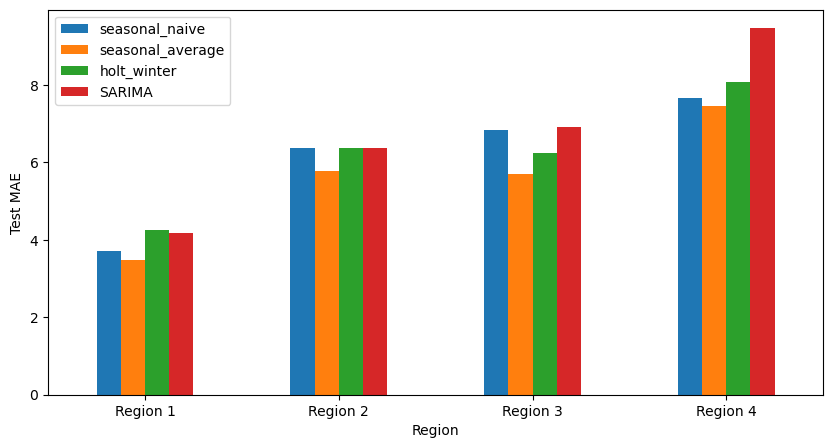

In [15]:
methods=["seasonal_naive", "seasonal_average", "holt_winter", "SARIMA"]
region_mean = all_scores.groupby("Region")[methods].mean()

region_mean.plot.bar(capsize=3, figsize=(10, 5))
plt.ylabel("Test MAE")
plt.xticks(rotation=0)
plt.show()

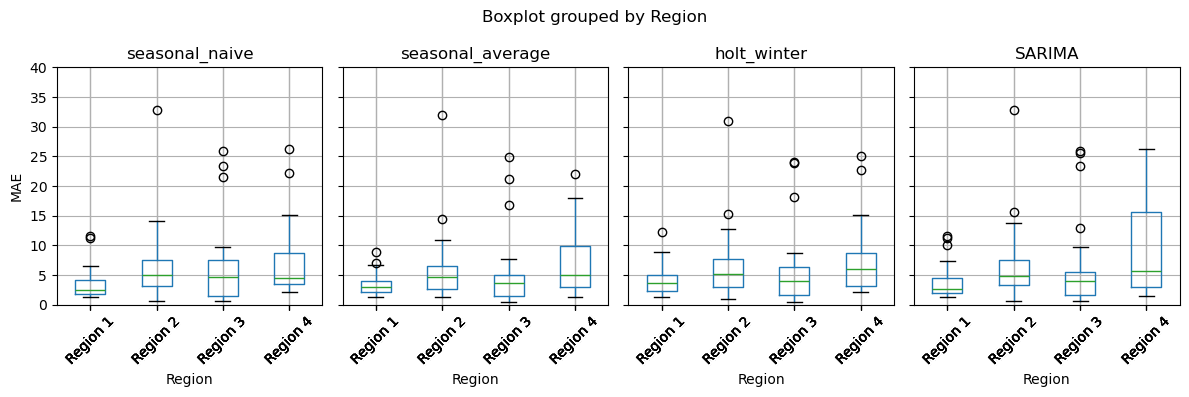

In [26]:
axes = all_scores.boxplot(column=methods, by="Region", layout=(1, 4), figsize=(12, 4), rot=45, sharey=True)
axes[0].set_ylabel("MAE")
plt.ylim(0, 40)
plt.tight_layout()
plt.show()

### Reading the box plots

Each box summarises the test MAE of all reactors in one region for one method:

- **Green line:** the median reactor. Half the reactors have a lower MAE, half a higher one.
- **Box:** the middle 50% of reactors, from the 25th to the 75th percentile. Its height is the interquartile range (IQR); a taller box means the reactors differ more from each other.
- **Whiskers:** they extend to the most extreme reactor within 1.5 × IQR of the box. They are often unequal, which shows the errors are skewed.
- **Circles:** outliers beyond the whiskers. Each circle is a single reactor with an unusually large error.

The medians across all 4 regions are comparable but As can be seen from this plot many region 4 reactors have large errors.


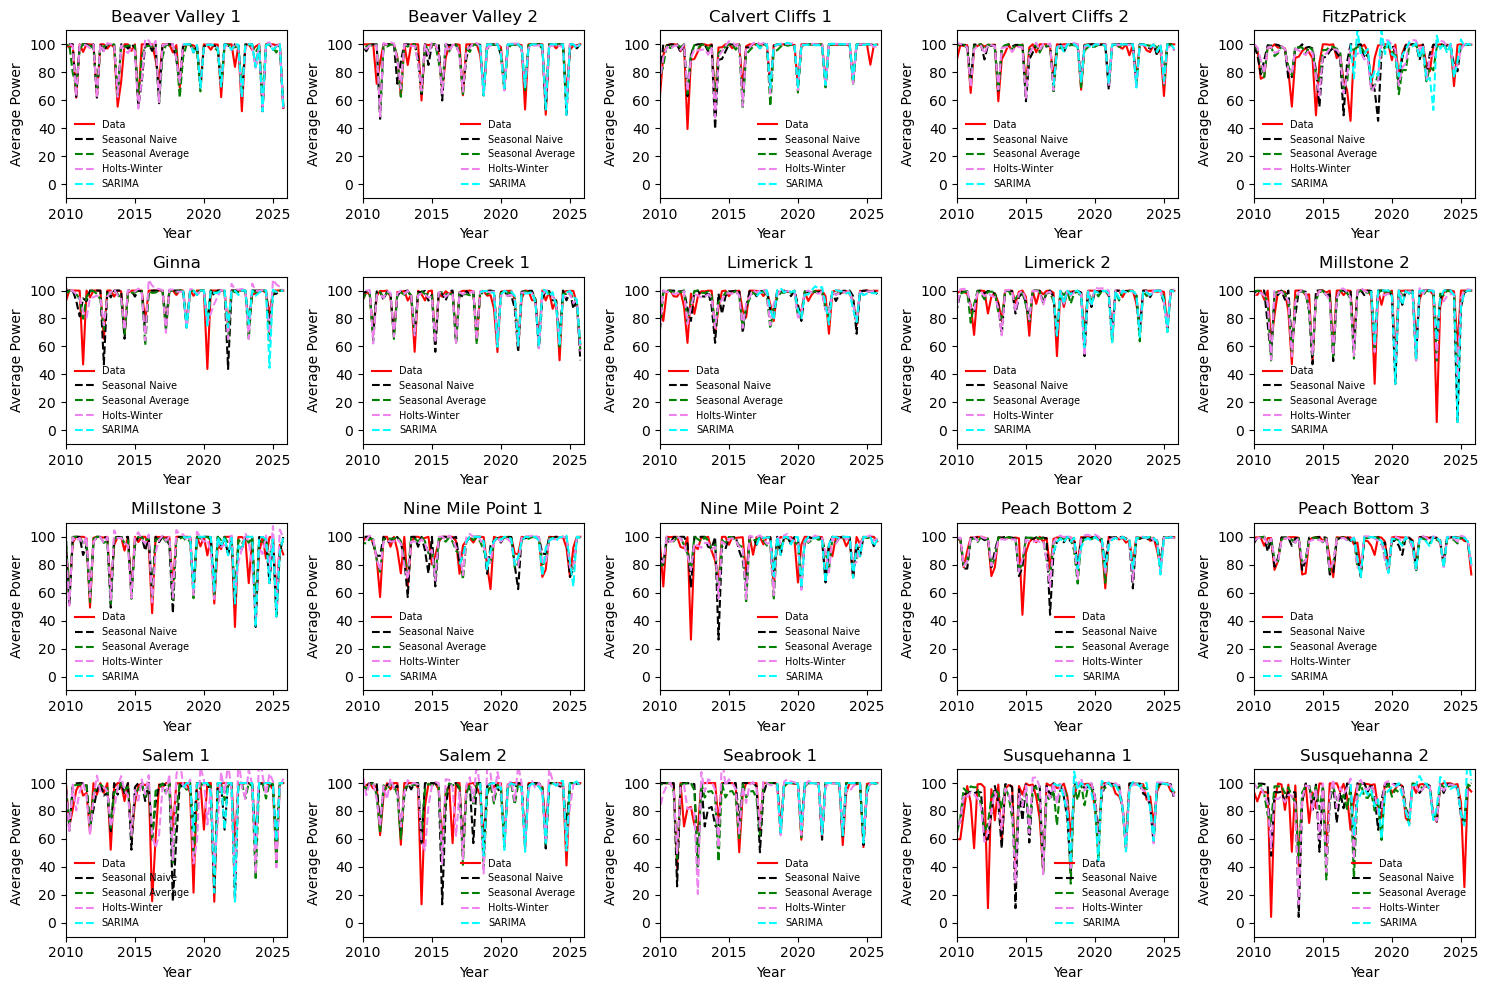

In [17]:
region = "Region 1"

regional_df = quarter_df[ quarter_df["Region"] == region ]
reactors = regional_df["Unit"].unique()

n_rows = 4
n_columns = math.ceil(len(reactors)/n_rows)

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 10))
axes = axes.flatten()

for i in range(len(reactors)):  

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["average_power"], color='red', label="Data" )

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["seasonal_naive"], '--', color='black', label="Seasonal Naive" )

    axes[i].plot( regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["seasonal_average"], '--', color='green', label="Seasonal Average")

    axes[i].plot(regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["holt_winter"], '--', color='violet', label="Holts-Winter")

    axes[i].plot(regional_df[ regional_df["Unit"] == reactors[i] ]["quarter_start"], regional_df[ regional_df["Unit"] == reactors[i] ]["arima"], '--', color='cyan', label="SARIMA")


    axes[i].legend(fontsize=7, frameon=False)
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Average Power")
    axes[i].set_title(f'{reactors[i]}')
    axes[i].set_ylim(-10, 110)
    axes[i].set_xlim(pd.Timestamp("2010-01-01"), pd.Timestamp("2026-01-01"))
    axes[i].xaxis.set_major_locator(mdates.YearLocator(5))

plt.tight_layout()
plt.show()

In [27]:
# Summary of the per-reactor test MAE for each model

mae_table = all_scores[methods].astype(float)
summary = mae_table.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T
summary.round(2)


,count,mean,std,min,25%,50%,75%,90%,max
seasonal_naive,92.0,6.15,6.04,0.58,2.53,4.33,6.97,11.55,32.87
seasonal_average,92.0,5.59,5.59,0.40,2.40,3.94,6.18,11.10,31.97
holt_winter,92.0,6.22,5.77,0.45,2.84,4.64,7.02,12.67,30.97
SARIMA,92.0,6.62,6.60,0.58,2.55,3.99,7.61,15.47,32.79


## Conclusions

Test MAE per reactor over 2023–2025, in percentage points of full power:


- **The simple seasonal average (k = 3) is the best univariate model.** It has the lowest mean, median (50th-percentile) and 90th-percentile error. Averaging the last few cycles smooths out one-off events, while staying recent enough to follow changes in cycle length.
- **The errors are concentrated in a few reactors.** For every model the mean is well above the median, and the worst reactor has an MAE above 30 points. All four models fail on these reactors in the same way: they can't predict unplanned outages, or refuelings that run much longer than usual because none of that can be seen in past power alone.

**Next step:** in `AdvancedForecasts` we add information beyond each reactor's own past power, such as the time since the last refueling, to see whether it reduces these large errors.
